In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/devrajkaransingh/uas-aerial/Testing Data/Labels/building-9-_jpg.rf.cd36cf662c8796fda5fbc784e9f4c675.txt
/kaggle/input/datasets/devrajkaransingh/uas-aerial/Testing Data/Labels/aircraft-6-_jpg.rf.4cc2d099985fd530cd49cdad5a9b2e81.txt
/kaggle/input/datasets/devrajkaransingh/uas-aerial/Testing Data/Labels/building-27-_jpg.rf.90f693560d357ae1a97529f48be76cef.txt
/kaggle/input/datasets/devrajkaransingh/uas-aerial/Testing Data/Labels/building-24-_jpg.rf.7c846ff0d2a4c940a72fb2a7b7c1013c.txt
/kaggle/input/datasets/devrajkaransingh/uas-aerial/Testing Data/Labels/tank-18-_jpg.rf.2f938858ca6dab25155334006f5d7854.txt
/kaggle/input/datasets/devrajkaransingh/uas-aerial/Testing Data/Labels/truck-3-_jpg.rf.878c09cff57b8805788e1e4fb2fe9af6.txt
/kaggle/input/datasets/devrajkaransingh/uas-aerial/Testing Data/Labels/aircraft-26-_jpg.rf.b8aad2d718660cf2f9702113912edbe1.txt
/kaggle/input/datasets/devrajkaransingh/uas-aerial/Testing Data/Labels/aircraft-13-_jpg.rf.e7805ba520edaae8deebcd9

In [1]:
!nvidia-smi

Tue Oct 13 05:13:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 4.2 MB/s eta 0:00:00


In [3]:
import os
DATA_ROOT = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training Data" in dirs:
        DATA_ROOT = root
        break
print("DATA_ROOT =", DATA_ROOT)

DATA_ROOT = /kaggle/input/datasets/devrajkaransingh/uas-aerial


In [4]:
splits = {"train": "Training Data", "val": "Validation Data", "test": "Testing Data"}
for key, folder in splits.items():
    imgs = os.listdir(f"{DATA_ROOT}/{folder}/Images")
    lbls = os.listdir(f"{DATA_ROOT}/{folder}/Labels")
    print(key, "| images:", len(imgs), "| labels:", len(lbls))

print(sorted(os.listdir(f"{DATA_ROOT}/Training Data/Images"))[:8])

train | images: 3168 | labels: 3168
val | images: 16 | labels: 16
test | images: 16 | labels: 16
['aircraft-1-_jpg.rf.8a4d3c9f141b580393f093f67ee5b3fb_brightness_1.jpg', 'aircraft-1-_jpg.rf.8a4d3c9f141b580393f093f67ee5b3fb_brightness_2.jpg', 'aircraft-1-_jpg.rf.8a4d3c9f141b580393f093f67ee5b3fb_brightness_3.jpg', 'aircraft-1-_jpg.rf.8a4d3c9f141b580393f093f67ee5b3fb_brightness_4.jpg', 'aircraft-1-_jpg.rf.8a4d3c9f141b580393f093f67ee5b3fb_brightness_5.jpg', 'aircraft-1-_jpg.rf.8a4d3c9f141b580393f093f67ee5b3fb_flip.jpg', 'aircraft-1-_jpg.rf.8a4d3c9f141b580393f093f67ee5b3fb_haze_1.jpg', 'aircraft-1-_jpg.rf.8a4d3c9f141b580393f093f67ee5b3fb_haze_2.jpg']


In [5]:
import shutil
OUT = "/kaggle/working/yolo_data"
if os.path.exists(OUT):
    shutil.rmtree(OUT)

for key, folder in splits.items():
    os.makedirs(f"{OUT}/images/{key}")
    os.makedirs(f"{OUT}/labels/{key}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Images"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Images/{f}", f"{OUT}/images/{key}/{f}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Labels"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Labels/{f}", f"{OUT}/labels/{key}/{f}")

yaml_text = """path: /kaggle/working/yolo_data
train: images/train
val: images/val
test: images/test

names:
  0: Aircraft
  1: Building
  2: Military Truck
  3: Tank
"""
with open("/kaggle/working/data.yaml", "w") as f:
    f.write(yaml_text)
print("Done. data.yaml written.")

Done. data.yaml written.


class 0 = Aircraft: 16740 objects
class 1 = Building: 18072 objects
class 2 = Military Truck: 6552 objects
class 3 = Tank: 7884 objects


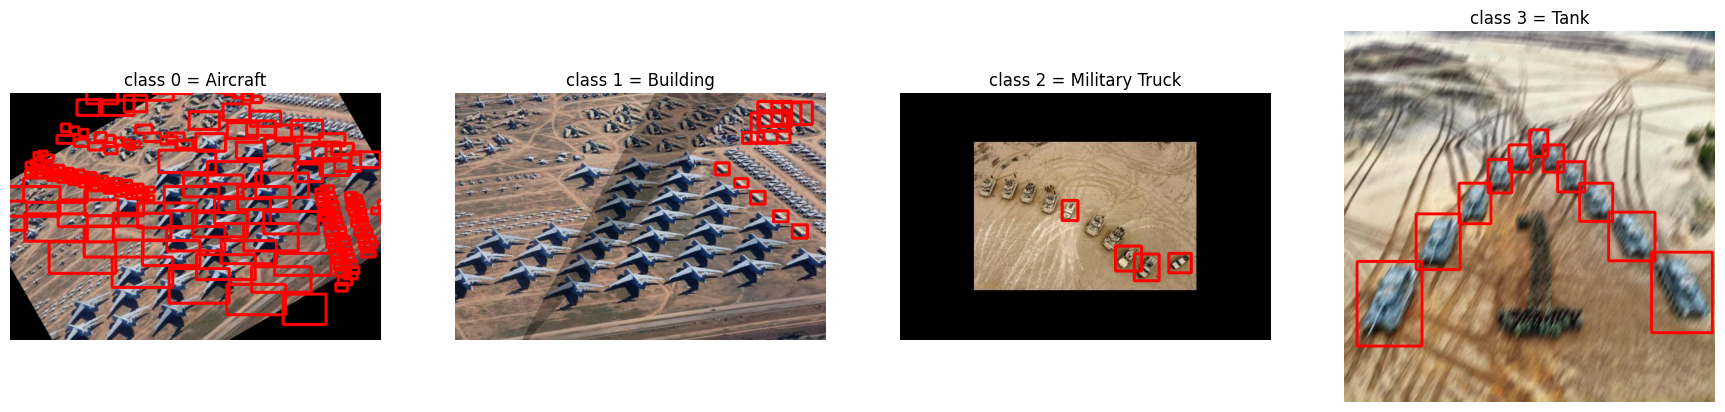

In [6]:
import cv2, random, collections
import matplotlib.pyplot as plt

names = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}
lbl_dir = f"{OUT}/labels/train"
counts = collections.Counter()
examples = {c: [] for c in names}

for f in os.listdir(lbl_dir):
    for line in open(f"{lbl_dir}/{f}"):
        p = line.split()
        if len(p) >= 5:
            c = int(float(p[0]))
            counts[c] += 1
            examples[c].append(f)

for c in names:
    print(f"class {c} = {names[c]}: {counts[c]} objects")

def find_img(stem):
    for ext in (".jpg", ".jpeg", ".png"):
        p = f"{OUT}/images/train/{stem}{ext}"
        if os.path.exists(p):
            return p

fig, axs = plt.subplots(1, 4, figsize=(22, 6))
for ax, c in zip(axs, names):
    f = random.choice(examples[c])
    img = cv2.cvtColor(cv2.imread(find_img(os.path.splitext(f)[0])), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    for line in open(f"{lbl_dir}/{f}"):
        p = line.split()
        if int(float(p[0])) == c:
            xc, yc, w, h = [float(v) for v in p[1:5]]
            cv2.rectangle(img, (int((xc-w/2)*W), int((yc-h/2)*H)),
                          (int((xc+w/2)*W), int((yc+h/2)*H)), (255, 0, 0), 3)
    ax.imshow(img)
    ax.set_title(f"class {c} = {names[c]}")
    ax.axis("off")
plt.show()

In [7]:
import re, collections

def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname)
    return m.group(1) if m else os.path.splitext(fname)[0]

def keys_of(split):
    return [source_key(f) for f in os.listdir(f"{OUT}/images/{split}")]

tr, va, te = keys_of("train"), keys_of("val"), keys_of("test")
tr_set = set(tr)
cnt = collections.Counter(tr)

print("train images:", len(tr), "| unique original photos:", len(tr_set))
print("variants per photo: min", min(cnt.values()), "max", max(cnt.values()))
print("val photos also in train:", len(set(va) & tr_set), "of", len(set(va)))
print("test photos also in train:", len(set(te) & tr_set), "of", len(set(te)))
print("val/test overlap:", len(set(va) & set(te)))

kinds = collections.Counter()
for f in os.listdir(f"{OUT}/images/train"):
    base = os.path.splitext(f)[0]
    rest = base[len(source_key(f)):]
    kinds[re.sub(r'_\d+$', '', rest) or "original"] += 1
print("augmentation types:", kinds.most_common())

print("val examples:", sorted(os.listdir(f"{OUT}/images/val"))[:4])
print("test examples:", sorted(os.listdir(f"{OUT}/images/test"))[:4])

train images: 3168 | unique original photos: 88
variants per photo: min 36 max 36
val photos also in train: 0 of 16
test photos also in train: 0 of 16
val/test overlap: 0
augmentation types: [('_haze', 440), ('_shadow', 440), ('_motionblur', 440), ('_zoom_in', 440), ('_zoom_out', 440), ('_rotation', 440), ('_brightness', 440), ('_flip', 88)]
val examples: ['aircraft-15-_jpg.rf.0cf42c02592feb59d0af1b634acfeb11.jpg', 'aircraft-2-_jpg.rf.aa2e15b668d5686f0f2a004b5211e43c.jpg', 'aircraft-23-_jpg.rf.efe45e2dae0fb3630cbaa732df810fcb.jpg', 'aircraft-25-_jpg.rf.aae32e1f34e40bd88e8591e5bad87622.jpg']
test examples: ['aircraft-13-_jpg.rf.e7805ba520edaae8deebcd98b4f74265.jpg', 'aircraft-22-_jpg.rf.6e93c0a69424aa222adb66e68db93e4b.jpg', 'aircraft-26-_jpg.rf.b8aad2d718660cf2f9702113912edbe1.jpg', 'aircraft-6-_jpg.rf.4cc2d099985fd530cd49cdad5a9b2e81.jpg']


In [8]:
# ===== CELL 8: ALL-IN-ONE PREP =====
import os, shutil, subprocess, sys, collections
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])

DATA_ROOT = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training Data" in dirs:
        DATA_ROOT = root
        break
assert DATA_ROOT, "Dataset not found: click Add Input and add uas-aerial"

OUT = "/kaggle/working/yolo_data"
if os.path.exists(OUT):
    shutil.rmtree(OUT)

splits = {"train": "Training Data", "val": "Validation Data", "test": "Testing Data"}
for key, folder in splits.items():
    os.makedirs(f"{OUT}/images/{key}")
    os.makedirs(f"{OUT}/labels/{key}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Images"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Images/{f}", f"{OUT}/images/{key}/{f}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Labels"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Labels/{f}", f"{OUT}/labels/{key}/{f}")

NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}
print("Dataset:", DATA_ROOT)
for key in splits:
    print(key, "images:", len(os.listdir(f"{OUT}/images/{key}")),
          "| labels:", len(os.listdir(f"{OUT}/labels/{key}")))
print("Class IDs:", NAMES)
print("PREP DONE")

Dataset: /kaggle/input/datasets/devrajkaransingh/uas-aerial
train images: 3168 | labels: 3168
val images: 16 | labels: 16
test images: 16 | labels: 16
Class IDs: {0: 'Aircraft', 1: 'Building', 2: 'Military Truck', 3: 'Tank'}
PREP DONE


In [9]:
# ===== CELL 9: PHOTO-LEVEL SPLIT =====
import re, random, collections, os, shutil
random.seed(42)

VAL_FRACTION = 0.20
KEEP_TYPES = None   # None = keep all augmentations.
                    # Later try e.g. ["flip","brightness","rotation","zoom_in","zoom_out"]

def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname)
    return m.group(1) if m else os.path.splitext(fname)[0]

def aug_type(fname):
    base = os.path.splitext(fname)[0]
    rest = re.sub(r'_\d+$', '', base[len(source_key(fname)):]).lstrip('_')
    return rest or "original"

def label_path(split_dir, fname):
    return f"{split_dir}/labels/{os.path.splitext(fname)[0]}.txt"

def link(src, dst):
    try:
        os.link(src, dst)
    except Exception:
        shutil.copy(src, dst)

# group train images by original photo
photos = collections.defaultdict(list)
for f in os.listdir(f"{OUT}/images/train"):
    photos[source_key(f)].append(f)

# dominant class of each photo (for a stratified split)
dom = {}
for k, files in photos.items():
    c = collections.Counter()
    for line in open(label_path(OUT, files[0]).replace("/labels/", "/labels/train/")):
        if line.strip():
            c[int(float(line.split()[0]))] += 1
    dom[k] = c.most_common(1)[0][0] if c else -1

by_class = collections.defaultdict(list)
for k, c in dom.items():
    by_class[c].append(k)

held = set()
for c, keys in by_class.items():
    random.shuffle(keys)
    n = max(1, round(VAL_FRACTION * len(keys)))
    held.update(keys[:n])

SPLIT = "/kaggle/working/yolo_split"
if os.path.exists(SPLIT):
    shutil.rmtree(SPLIT)
for s in ["train", "val", "test"]:
    os.makedirs(f"{SPLIT}/images/{s}")
    os.makedirs(f"{SPLIT}/labels/{s}")

def put(split_src, split_dst, fname):
    link(f"{OUT}/images/{split_src}/{fname}", f"{SPLIT}/images/{split_dst}/{fname}")
    lbl = os.path.splitext(fname)[0] + ".txt"
    link(f"{OUT}/labels/{split_src}/{lbl}", f"{SPLIT}/labels/{split_dst}/{lbl}")

# train: all (or chosen) variants of non-held photos
for k, files in photos.items():
    if k in held:
        continue
    for f in files:
        if KEEP_TYPES is None or aug_type(f) in KEEP_TYPES:
            put("train", "train", f)

# val: official 16 clean val images + the flip variant of each held-out photo
for f in os.listdir(f"{OUT}/images/val"):
    put("val", "val", f)
for k in held:
    flips = [f for f in photos[k] if aug_type(f) == "flip"]
    put("train", "val", (flips or photos[k])[0])

# test: official test, untouched
for f in os.listdir(f"{OUT}/images/test"):
    put("test", "test", f)

yaml_text = """path: /kaggle/working/yolo_split
train: images/train
val: images/val
test: images/test

names:
  0: Aircraft
  1: Building
  2: Military Truck
  3: Tank
"""
open("/kaggle/working/data_split.yaml", "w").write(yaml_text)

# report
def count_objs(s):
    c = collections.Counter()
    for f in os.listdir(f"{SPLIT}/labels/{s}"):
        for line in open(f"{SPLIT}/labels/{s}/{f}"):
            if line.strip():
                c[int(float(line.split()[0]))] += 1
    return c

print("Photos total:", len(photos), "| held out for val:", len(held))
print("Held-out photos per class:", {NAMES[c]: sum(dom[k] == c for k in held) for c in NAMES})
for s in ["train", "val", "test"]:
    oc = count_objs(s)
    print(f"{s}: {len(os.listdir(f'{SPLIT}/images/{s}'))} images | objects:",
          {NAMES[c]: oc[c] for c in NAMES})

Photos total: 88 | held out for val: 18
Held-out photos per class: {'Aircraft': 4, 'Building': 5, 'Military Truck': 4, 'Tank': 5}
train: 2520 images | objects: {'Aircraft': 8244, 'Building': 14760, 'Military Truck': 4392, 'Tank': 7200}
val: 34 images | objects: {'Aircraft': 244, 'Building': 160, 'Military Truck': 83, 'Tank': 26}
test: 16 images | objects: {'Aircraft': 36, 'Building': 56, 'Military Truck': 22, 'Tank': 19}


In [10]:
# ===== CELL 10: TRAIN EXPERIMENT 1 (yolov8s, all augmentations) =====
from ultralytics import YOLO
model = YOLO("yolov8s.pt")
model.train(
    data="/kaggle/working/data_split.yaml",
    epochs=60,
    patience=30,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/kaggle/working/runs",
    name="exp1_all_s",
    seed=0,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_split.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/60      5.32G      1.404      1.201      1.181        239        640: 100% ━━━━━━━━━━━━ 153/153 4.8it/s 32.1s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.6it/s 0.4s1.3s
                   all         33        497      0.575      0.217      0.209       0.11

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/60      5.34G      1.353      1.121      1.145        307        640: 100% ━━━━━━━━━━━━ 153/153 4.7it/s 32.3s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.6it/s 0.4s1.2s
                   all         33        497      0.346      0.236      0.202      0.126

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/60      5.34G      1.287      1.042      1.117        385        640: 100% ━━━━━━━━━━━━ 153/153 4.6it/s 33.6s0.2ss
                 Class     Images 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x793ae3164a60>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [11]:
# ===== CELL 11: EVALUATE =====
from ultralytics import YOLO
import shutil
best = YOLO("/kaggle/working/runs/exp1_all_s/weights/best.pt")

for split in ["val", "test"]:
    m = best.val(data="/kaggle/working/data_split.yaml", split=split,
                 imgsz=640, device=0, plots=False, verbose=False)
    print("\n=====", split.upper(), "=====")
    print(f"Precision {m.box.mp:.3f} | Recall {m.box.mr:.3f} | "
          f"mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")
    for i, c in enumerate(m.box.ap_class_index):
        print(f"  {best.names[int(c)]}: AP50 = {m.box.ap50[i]:.3f}")

shutil.copy("/kaggle/working/runs/exp1_all_s/weights/best.pt", "/kaggle/working/exp1_best.pt")
print("\nSaved /kaggle/working/exp1_best.pt")

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1679.1±376.0 MB/s, size: 78.8 KB)
val: Scanning /kaggle/working/yolo_split/labels/val.cache... 34 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 34/34 10.2Mit/s 0.0s
val: /kaggle/working/yolo_split/images/val/truck-4-_jpg.rf.b20a78c9850a98f1586a82137a80dbcf.jpg: ignoring corrupt image/label: labels mix segment and detection rows
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 4.0it/s 0.8s0.6s
                   all         33        497       0.51       0.32      0.291       0.17
Speed: 0.9ms preprocess, 11.3ms inference, 0.0ms loss, 1.3ms postprocess per image

===== VAL =====
Precision 0.510 | Recall 0.320 | mAP50 0.291 | mAP50-95 0.170
  Aircraft: AP50 = 0.315
  Building: AP50 = 0.431
  Military Truck: 

In [12]:
# ===== CELL 12: DIAGNOSTICS =====
import os, collections, numpy as np
from PIL import Image
from ultralytics import YOLO

OUT = "/kaggle/working/yolo_data"
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

# A) do the class numbers mean what we think? (file names start with the class name)
pref = collections.defaultdict(collections.Counter)
for split in ["train", "val", "test"]:
    for f in os.listdir(f"{OUT}/labels/{split}"):
        key = f.split("-")[0].lower()
        for line in open(f"{OUT}/labels/{split}/{f}"):
            p = line.split()
            if len(p) >= 5:
                pref[key][int(float(p[0]))] += 1
print("A) class numbers found inside files, grouped by file-name prefix:")
for key, cnt in sorted(pref.items()):
    print(f"   {key:10s} -> {dict(cnt)}")

# B) object sizes
def size_report(split):
    img_dir, lbl_dir = f"{OUT}/images/{split}", f"{OUT}/labels/{split}"
    rec = {c: [] for c in NAMES}
    dims = collections.Counter()
    for f in os.listdir(img_dir):
        with Image.open(f"{img_dir}/{f}") as im:
            W, H = im.size
        dims[(W, H)] += 1
        lp = f"{lbl_dir}/{os.path.splitext(f)[0]}.txt"
        if not os.path.exists(lp):
            continue
        for line in open(lp):
            p = line.split()
            if len(p) == 5 and int(float(p[0])) in rec:
                rec[int(float(p[0]))].append((max(float(p[3]) * W, float(p[4]) * H), max(W, H)))
    return dims, rec

print("\nB) object sizes (longest side of each box)")
for split in ["train", "test"]:
    dims, rec = size_report(split)
    print(f" {split}: most common image sizes {dims.most_common(3)}")
    for c, arr in rec.items():
        if not arr:
            continue
        a = np.array(arr)
        s640, s1280 = a[:, 0] * 640 / a[:, 1], a[:, 0] * 1280 / a[:, 1]
        print(f"   {NAMES[c]:15s} median {np.median(a[:,0]):4.0f}px native | {np.median(s640):4.0f}px at 640 | "
              f"under 32px: {np.mean(s640 < 32)*100:3.0f}% at 640, {np.mean(s1280 < 32)*100:3.0f}% at 1280")

# C) what happens to the Military Truck objects in TEST?
def gt_boxes(lp, W, H):
    out = []
    for line in open(lp):
        p = line.split()
        if len(p) == 5:
            c = int(float(p[0])); xc, yc, w, h = [float(v) for v in p[1:]]
            out.append((c, (xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H))
    return out

def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0

if os.path.exists("/kaggle/working/exp1_best.pt"):
    model = YOLO("/kaggle/working/exp1_best.pt")
    summary = collections.Counter()
    print("\nC) Military Truck objects in TEST: missed, or called something else?")
    for f in sorted(os.listdir(f"{OUT}/images/test")):
        p = f"{OUT}/images/test/{f}"
        with Image.open(p) as im:
            W, H = im.size
        gts = [g for g in gt_boxes(f"{OUT}/labels/test/{os.path.splitext(f)[0]}.txt", W, H) if g[0] == 2]
        if not gts:
            continue
        r = model.predict(p, conf=0.05, imgsz=640, verbose=False)[0]
        preds = [(int(c), float(s), b.tolist()) for c, s, b in zip(r.boxes.cls, r.boxes.conf, r.boxes.xyxy)]
        print(" ", f[:40])
        for g in gts:
            best, best_iou = None, 0
            for c, s, b in preds:
                i = iou(g[1:], b)
                if i > best_iou:
                    best, best_iou = (c, s), i
            size = f"{g[3]-g[1]:.0f}x{g[4]-g[2]:.0f}px"
            if best is None or best_iou < 0.3:
                summary["missed"] += 1
                print(f"     truck {size}: MISSED")
            else:
                tag = "right class" if best[0] == 2 else "WRONG class"
                summary[tag] += 1
                print(f"     truck {size}: predicted {NAMES[best[0]]} conf {best[1]:.2f} IoU {best_iou:.2f} -> {tag}")
    print(dict(summary))
else:
    print("exp1_best.pt not found, skipping part C")

A) class numbers found inside files, grouped by file-name prefix:
   aircraft   -> {0: 16636, 1: 2670, 2: 1332, 3: 612}
   building   -> {1: 14766, 0: 108, 2: 1620}
   tank       -> {3: 6175, 2: 1044, 1: 108, 0: 1}
   truck      -> {2: 2601, 0: 39, 3: 1123, 1: 652}

B) object sizes (longest side of each box)
 train: most common image sizes [((2560, 2560), 612), ((640, 640), 324), ((416, 416), 180)]
   Aircraft        median   36px native |   33px at 640 | under 32px:  49% at 640,  11% at 1280
   Building        median  134px native |   53px at 640 | under 32px:  26% at 640,   4% at 1280
   Military Truck  median   46px native |   32px at 640 | under 32px:  49% at 640,  12% at 1280
   Tank            median   87px native |   64px at 640 | under 32px:  11% at 640,   8% at 1280
 test: most common image sizes [((2048, 2048), 3), ((1000, 700), 2), ((640, 640), 2)]
   Aircraft        median   59px native |   47px at 640 | under 32px:  11% at 640,   3% at 1280
   Building        median  212px

In [13]:
# ===== CELL 13: CLEAN LABELS + EXPERIMENT TOOLKIT =====
import os, re, json, time, random, shutil, collections

OUT = "/kaggle/working/yolo_data"
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

def clean_label_file(path):
    rows, changed = [], False
    for line in open(path):
        p = line.split()
        if not p:
            continue
        try:
            c = int(float(p[0])); v = [float(x) for x in p[1:]]
        except ValueError:
            changed = True; continue
        if len(v) == 4:
            x1, y1, x2, y2 = v[0]-v[2]/2, v[1]-v[3]/2, v[0]+v[2]/2, v[1]+v[3]/2
        elif len(v) >= 6 and len(v) % 2 == 0:          # polygon row -> bounding box
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
            changed = True
        else:
            changed = True; continue
        cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)   # clip to image
        if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2):
            changed = True
        w, h = cx2 - cx1, cy2 - cy1
        if w < 0.002 or h < 0.002:
            changed = True; continue
        rows.append(f"{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {w:.6f} {h:.6f}")
    return rows, changed

for split in ["train", "val"]:                          # test labels stay untouched
    d = f"{OUT}/labels/{split}"
    fixed = 0
    for f in os.listdir(d):
        rows, changed = clean_label_file(f"{d}/{f}")
        if changed:
            fixed += 1
            with open(f"{d}/{f}", "w") as fh:
                fh.write("\n".join(rows) + ("\n" if rows else ""))
    print(f"{split}: fixed {fixed} of {len(os.listdir(d))} label files")

def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname)
    return m.group(1) if m else os.path.splitext(fname)[0]

def aug_type(fname):
    rest = os.path.splitext(fname)[0][len(source_key(fname)):]
    return re.sub(r'_\d+$', '', rest).lstrip('_') or "original"

ALL_TYPES = ["flip", "brightness", "haze", "shadow", "motionblur", "zoom_in", "zoom_out", "rotation"]
HELD_PATH = "/kaggle/working/held_photos.json"

def build_split(keep_types, per_type, val_fraction=0.20):
    SPLIT = "/kaggle/working/yolo_split"
    photos = collections.defaultdict(list)
    for f in sorted(os.listdir(f"{OUT}/images/train")):
        photos[source_key(f)].append(f)

    if os.path.exists(HELD_PATH):                       # same held-out photos for every experiment
        held = set(json.load(open(HELD_PATH)))
    else:
        dom = {}
        for k, files in photos.items():
            cnt = collections.Counter()
            stem = os.path.splitext(files[0])[0]
            for line in open(f"{OUT}/labels/train/{stem}.txt"):
                p = line.split()
                if len(p) >= 5:
                    cnt[int(float(p[0]))] += 1
            dom[k] = cnt.most_common(1)[0][0] if cnt else -1
        rng, held = random.Random(42), set()
        for c in sorted(set(dom.values())):
            keys = sorted(k for k, v in dom.items() if v == c)
            rng.shuffle(keys)
            held.update(keys[:max(1, round(val_fraction * len(keys)))])
        json.dump(sorted(held), open(HELD_PATH, "w"))

    if os.path.exists(SPLIT):
        shutil.rmtree(SPLIT)
    for s in ["train", "val", "test"]:
        os.makedirs(f"{SPLIT}/images/{s}"); os.makedirs(f"{SPLIT}/labels/{s}")

    def put(src_split, dst_split, fname):
        stem = os.path.splitext(fname)[0]
        for kind, name in (("images", fname), ("labels", stem + ".txt")):
            src, dst = f"{OUT}/{kind}/{src_split}/{name}", f"{SPLIT}/{kind}/{dst_split}/{name}"
            try:
                os.link(src, dst)
            except OSError:
                shutil.copy(src, dst)

    for k, files in photos.items():
        if k in held:
            continue
        taken = collections.Counter()
        for f in files:
            t = aug_type(f)
            if t in keep_types and taken[t] < per_type:
                put("train", "train", f); taken[t] += 1
    for f in os.listdir(f"{OUT}/images/val"):
        put("val", "val", f)
    for k in held:
        flips = [f for f in photos[k] if aug_type(f) == "flip"]
        put("train", "val", (flips or photos[k])[0])
    for f in os.listdir(f"{OUT}/images/test"):
        put("test", "test", f)

    yaml_path = "/kaggle/working/data_split.yaml"
    with open(yaml_path, "w") as fh:
        fh.write(f"path: {SPLIT}\ntrain: images/train\nval: images/val\ntest: images/test\n\n"
                 "names:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    for s in ["train", "val", "test"]:
        cnt = collections.Counter()
        for f in os.listdir(f"{SPLIT}/labels/{s}"):
            for line in open(f"{SPLIT}/labels/{s}/{f}"):
                p = line.split()
                if len(p) >= 5:
                    cnt[int(float(p[0]))] += 1
        n_img = len(os.listdir(f"{SPLIT}/images/{s}"))
        print(f"  {s}: {n_img} images | " + ", ".join(f"{NAMES[c]} {cnt[c]}" for c in NAMES))
    return yaml_path

RESULTS_PATH = "/kaggle/working/results.json"
results_log = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
results_log.setdefault("exp1_ref", {"minutes": 26,
    "val": {"P": 0.510, "R": 0.320, "map50": 0.291, "map5095": 0.170, "ap50": {}},
    "test": {"P": 0.640, "R": 0.360, "map50": 0.433, "map5095": 0.226,
             "ap50": {"Aircraft": 0.628, "Building": 0.633, "Military Truck": 0.011, "Tank": 0.458}}})

def run_experiment(cfg):
    from ultralytics import YOLO
    t0 = time.time()
    print("\n" + "=" * 70); print("EXPERIMENT", cfg["name"], cfg); print("=" * 70)
    yaml_path = build_split(cfg["keep"], cfg["per_type"])
    YOLO(cfg["model"]).train(
        data=yaml_path, epochs=cfg["epochs"], patience=30, imgsz=cfg["imgsz"], batch=cfg["batch"],
        device=0, workers=2, project="/kaggle/working/runs", name=cfg["name"], exist_ok=True,
        seed=0, flipud=0.5, cos_lr=True, plots=False)
    best_path = f"/kaggle/working/runs/{cfg['name']}/weights/best.pt"
    best = YOLO(best_path)
    out = {"minutes": round((time.time() - t0) / 60, 1)}
    for split in ["val", "test"]:
        r = best.val(data=yaml_path, split=split, imgsz=cfg["imgsz"], device=0, plots=False, verbose=False)
        out[split] = {"P": float(r.box.mp), "R": float(r.box.mr), "map50": float(r.box.map50),
                      "map5095": float(r.box.map),
                      "ap50": {best.names[int(c)]: float(r.box.ap50[i]) for i, c in enumerate(r.box.ap_class_index)}}
    shutil.copy(best_path, f"/kaggle/working/{cfg['name']}_best.pt")
    results_log[cfg["name"]] = out
    json.dump(results_log, open(RESULTS_PATH, "w"), indent=1)
    return out

def show_summary():
    head = f"{'experiment':15s}|{'VAL mAP50':>10s} |{'TEST P':>7s}{'R':>6s}{'mAP50':>7s}{'mAP5095':>8s} |"
    head += "".join(f"{NAMES[c][:8]:>9s}" for c in NAMES) + " | min"
    print(head)
    for name, o in results_log.items():
        t = o["test"]
        row = f"{name:15s}|{o['val']['map50']:10.3f} |{t['P']:7.3f}{t['R']:6.3f}{t['map50']:7.3f}{t['map5095']:8.3f} |"
        row += "".join(f"{t['ap50'].get(NAMES[c], 0):9.3f}" for c in NAMES) + f" | {o['minutes']}"
        print(row)
print("Toolkit ready.")

train: fixed 785 of 3168 label files
val: fixed 1 of 16 label files
Toolkit ready.


In [14]:
CONFIGS = [
    dict(name="e2_s640",  model="yolov8s.pt", imgsz=640,  batch=16, epochs=100, keep=ALL_TYPES, per_type=1),
    dict(name="e3_s1024", model="yolov8s.pt", imgsz=1024, batch=8,  epochs=100, keep=ALL_TYPES, per_type=1),
    # only if e3 beats e2 (about 70+ min):
    # dict(name="e4_m1024", model="yolov8m.pt", imgsz=1024, batch=8, epochs=100, keep=ALL_TYPES, per_type=1),
]
for cfg in CONFIGS:
    if cfg["name"] in results_log:
        print("skip (already done):", cfg["name"]); continue
    try:
        run_experiment(cfg)
    except Exception as e:
        print("FAILED", cfg["name"], repr(e))
show_summary()


EXPERIMENT e2_s640 {'name': 'e2_s640', 'model': 'yolov8s.pt', 'imgsz': 640, 'batch': 16, 'epochs': 100, 'keep': ['flip', 'brightness', 'haze', 'shadow', 'motionblur', 'zoom_in', 'zoom_out', 'rotation'], 'per_type': 1}
  train: 560 images | Aircraft 3047, Building 3234, Military Truck 831, Tank 1227
  val: 34 images | Aircraft 91, Building 163, Military Truck 101, Tank 72
  test: 16 images | Aircraft 36, Building 56, Military Truck 22, Tank 19
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data_split.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dl

In [15]:
# ===== CELL 15: TOOLKIT WITH EXTRA TRAINING OPTIONS =====
def run_experiment(cfg):
    from ultralytics import YOLO
    t0 = time.time()
    print("\n" + "=" * 70); print("EXPERIMENT", cfg["name"]); print(cfg); print("=" * 70)
    yaml_path = build_split(cfg["keep"], cfg["per_type"])
    args = dict(data=yaml_path, epochs=cfg["epochs"], patience=30, imgsz=cfg["imgsz"],
                batch=cfg["batch"], device=0, workers=2, project="/kaggle/working/runs",
                name=cfg["name"], exist_ok=True, seed=0, flipud=0.5, cos_lr=True, plots=False)
    args.update(cfg.get("extra", {}))
    YOLO(cfg["model"]).train(**args)
    best_path = f"/kaggle/working/runs/{cfg['name']}/weights/best.pt"
    best = YOLO(best_path)
    out = {"minutes": round((time.time() - t0) / 60, 1)}
    for split in ["val", "test"]:
        r = best.val(data=yaml_path, split=split, imgsz=cfg["imgsz"], device=0, plots=False, verbose=False)
        out[split] = {"P": float(r.box.mp), "R": float(r.box.mr), "map50": float(r.box.map50),
                      "map5095": float(r.box.map),
                      "ap50": {best.names[int(c)]: float(r.box.ap50[i]) for i, c in enumerate(r.box.ap_class_index)}}
    shutil.copy(best_path, f"/kaggle/working/{cfg['name']}_best.pt")
    results_log[cfg["name"]] = out
    json.dump(results_log, open(RESULTS_PATH, "w"), indent=1)
    return out
print("run_experiment upgraded")

run_experiment upgraded


In [16]:
CONFIGS = [
    dict(name="e4_s640_freeze", model="yolov8s.pt", imgsz=640, batch=16, epochs=100,
         keep=ALL_TYPES, per_type=1,
         extra=dict(freeze=10, lr0=0.001, optimizer="AdamW")),
    dict(name="e5_s640_aug", model="yolov8s.pt", imgsz=640, batch=16, epochs=100,
         keep=ALL_TYPES, per_type=1,
         extra=dict(mixup=0.15, scale=0.7, degrees=10, translate=0.2, hsv_s=0.8, hsv_v=0.5)),
    dict(name="e6_m640", model="yolov8m.pt", imgsz=640, batch=16, epochs=100,
         keep=ALL_TYPES, per_type=1),
]
for cfg in CONFIGS:
    if cfg["name"] in results_log:
        print("skip (already done):", cfg["name"]); continue
    try:
        run_experiment(cfg)
    except Exception as e:
        print("FAILED", cfg["name"], repr(e))
show_summary()


EXPERIMENT e4_s640_freeze
{'name': 'e4_s640_freeze', 'model': 'yolov8s.pt', 'imgsz': 640, 'batch': 16, 'epochs': 100, 'keep': ['flip', 'brightness', 'haze', 'shadow', 'motionblur', 'zoom_in', 'zoom_out', 'rotation'], 'per_type': 1, 'extra': {'freeze': 10, 'lr0': 0.001, 'optimizer': 'AdamW'}}
  train: 560 images | Aircraft 3047, Building 3234, Military Truck 831, Tank 1227
  val: 34 images | Aircraft 91, Building 163, Military Truck 101, Tank 72
  test: 16 images | Aircraft 36, Building 56, Military Truck 22, Tank 19
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data_split.yaml, degrees=0.0, deterministic=Tr

In [17]:

# ===== CELL 17: FINAL MODEL ON ALL PHOTOS =====
from ultralytics import YOLO

# Winner: e5_s640_aug
FINAL = dict(
    name="final",
    model="yolov8s.pt",
    imgsz=640,
    batch=16,
    epochs=40,
    keep=ALL_TYPES,
    per_type=1,
    extra=dict(
        mixup=0.15,
        scale=0.7,
        degrees=10,
        translate=0.2,
        hsv_s=0.8,
        hsv_v=0.5
    )
)

def build_final_split(keep_types, per_type):
    SPLIT = "/kaggle/working/yolo_final"

    if os.path.exists(SPLIT):
        shutil.rmtree(SPLIT)

    for s in ["train", "val", "test"]:
        os.makedirs(f"{SPLIT}/images/{s}")
        os.makedirs(f"{SPLIT}/labels/{s}")

    def put(src_split, dst_split, fname):
        stem = os.path.splitext(fname)[0]

        for kind, name in (
            ("images", fname),
            ("labels", stem + ".txt")
        ):
            src = f"{OUT}/{kind}/{src_split}/{name}"
            dst = f"{SPLIT}/{kind}/{dst_split}/{name}"

            try:
                os.link(src, dst)
            except OSError:
                shutil.copy(src, dst)

    photos = collections.defaultdict(list)

    for f in sorted(os.listdir(f"{OUT}/images/train")):
        photos[source_key(f)].append(f)

    # Use one image per augmentation type for each training photo
    for k, files in photos.items():
        taken = collections.Counter()

        for f in files:
            t = aug_type(f)

            if t in keep_types and taken[t] < per_type:
                put("train", "train", f)
                taken[t] += 1

    # Add official validation photos to training.
    # Keep validation copies as a placeholder for YOLO.
    for f in os.listdir(f"{OUT}/images/val"):
        put("val", "train", f)
        put("val", "val", f)

    # Keep test data separate and untouched
    for f in os.listdir(f"{OUT}/images/test"):
        put("test", "test", f)

    yaml_path = "/kaggle/working/data_final.yaml"

    with open(yaml_path, "w") as f:
        f.write(
            f"path: {SPLIT}\n"
            "train: images/train\n"
            "val: images/val\n"
            "test: images/test\n\n"
            "names:\n"
            "  0: Aircraft\n"
            "  1: Building\n"
            "  2: Military Truck\n"
            "  3: Tank\n"
        )

    print(
        "Final training images:",
        len(os.listdir(f"{SPLIT}/images/train")),
        "| Test images:",
        len(os.listdir(f"{SPLIT}/images/test"))
    )

    print("Class mapping:")
    print("0 = Aircraft")
    print("1 = Building")
    print("2 = Military Truck")
    print("3 = Tank")

    return yaml_path


yaml_path = build_final_split(
    FINAL["keep"],
    FINAL["per_type"]
)

args = dict(
    data=yaml_path,
    epochs=FINAL["epochs"],
    patience=0,
    imgsz=FINAL["imgsz"],
    batch=FINAL["batch"],
    device=0,
    workers=2,
    project="/kaggle/working/runs",
    name="final",
    exist_ok=True,
    seed=0,
    flipud=0.5,
    cos_lr=True,
    plots=False
)

# Apply Experiment 5's training settings
args.update(FINAL["extra"])

# Train the final model
YOLO(FINAL["model"]).train(**args)

# Load the final epoch's weights
final = YOLO(
    "/kaggle/working/runs/final/weights/last.pt"
)

# Evaluate on the untouched test set
r = final.val(
    data=yaml_path,
    split="test",
    imgsz=FINAL["imgsz"],
    device=0,
    plots=False,
    verbose=False
)

print("\n===== FINAL MODEL ON THE UNTOUCHED TEST SET =====")
print(f"Precision: {r.box.mp:.3f}")
print(f"Recall:    {r.box.mr:.3f}")
print(f"mAP50:     {r.box.map50:.3f}")
print(f"mAP50-95:  {r.box.map:.3f}")

for i, c in enumerate(r.box.ap_class_index):
    print(
        f"  {final.names[int(c)]}: "
        f"AP50 = {r.box.ap50[i]:.3f}"
    )

# Save model for download
shutil.copy(
    "/kaggle/working/runs/final/weights/last.pt",
    "/kaggle/working/final_model.pt"
)

print("\nSaved /kaggle/working/final_model.pt")


Final training images: 720 | Test images: 16
Class mapping:
0 = Aircraft
1 = Building
2 = Military Truck
3 = Tank
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data_final.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.8, hsv_v=0.5, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolov8s

In [18]:

from IPython.display import FileLink, display

display(FileLink('/kaggle/working/final_model.pt'))


/kaggle/working/final_model.pt

In [19]:

import os
import zipfile
from IPython.display import FileLink, display

model_path = "/kaggle/working/final_model.pt"
zip_path = "/kaggle/working/final_model_download.zip"

if os.path.exists(model_path):
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(model_path, arcname="final_model.pt")
    print("ZIP created successfully.")
    print("Model size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
    display(FileLink(zip_path))
else:
    print("Model file not found. Check whether the Kaggle session is still running.")


ZIP created successfully.
Model size: 21.48 MB


/kaggle/working/final_model_download.zip

In [6]:
# ===== ALL-IN-ONE: PREP + TOOLKIT + e7 =====
import os, re, json, time, random, shutil, subprocess, sys, collections
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import torch
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU T4 x2 in session options, then re-run"

# ---------- 1. copy data into YOLO layout ----------
DATA_ROOT = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training Data" in dirs:
        DATA_ROOT = root
        break
assert DATA_ROOT, "Dataset not found: click Add Input and add uas-aerial"

OUT = "/kaggle/working/yolo_data"
if os.path.exists(OUT):
    shutil.rmtree(OUT)
splits = {"train": "Training Data", "val": "Validation Data", "test": "Testing Data"}
for key, folder in splits.items():
    os.makedirs(f"{OUT}/images/{key}")
    os.makedirs(f"{OUT}/labels/{key}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Images"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Images/{f}", f"{OUT}/images/{key}/{f}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Labels"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Labels/{f}", f"{OUT}/labels/{key}/{f}")

NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

# ---------- 2. clean labels (train and val only; test is left untouched) ----------
def clean_label_file(path):
    rows, changed = [], False
    for line in open(path):
        p = line.split()
        if not p:
            continue
        try:
            c = int(float(p[0])); v = [float(x) for x in p[1:]]
        except ValueError:
            changed = True; continue
        if len(v) == 4:
            x1, y1, x2, y2 = v[0]-v[2]/2, v[1]-v[3]/2, v[0]+v[2]/2, v[1]+v[3]/2
        elif len(v) >= 6 and len(v) % 2 == 0:          # polygon row -> bounding box
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
            changed = True
        else:
            changed = True; continue
        cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)
        if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2):
            changed = True
        w, h = cx2 - cx1, cy2 - cy1
        if w < 0.002 or h < 0.002:
            changed = True; continue
        rows.append(f"{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {w:.6f} {h:.6f}")
    return rows, changed

for split in ["train", "val"]:
    d = f"{OUT}/labels/{split}"
    fixed = 0
    for f in os.listdir(d):
        rows, changed = clean_label_file(f"{d}/{f}")
        if changed:
            fixed += 1
            with open(f"{d}/{f}", "w") as fh:
                fh.write("\n".join(rows) + ("\n" if rows else ""))
    print(f"{split}: fixed {fixed} of {len(os.listdir(d))} label files")

# ---------- 3. helpers + split builder ----------
def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname)
    return m.group(1) if m else os.path.splitext(fname)[0]

def aug_type(fname):
    rest = os.path.splitext(fname)[0][len(source_key(fname)):]
    return re.sub(r'_\d+$', '', rest).lstrip('_') or "original"

ALL_TYPES = ["flip", "brightness", "haze", "shadow", "motionblur", "zoom_in", "zoom_out", "rotation"]
HELD_PATH = "/kaggle/working/held_photos.json"

def build_split(keep_types, per_type, val_fraction=0.20):
    SPLIT = "/kaggle/working/yolo_split"
    photos = collections.defaultdict(list)
    for f in sorted(os.listdir(f"{OUT}/images/train")):
        photos[source_key(f)].append(f)

    if os.path.exists(HELD_PATH):
        held = set(json.load(open(HELD_PATH)))
    else:
        dom = {}
        for k, files in photos.items():
            cnt = collections.Counter()
            stem = os.path.splitext(files[0])[0]
            for line in open(f"{OUT}/labels/train/{stem}.txt"):
                p = line.split()
                if len(p) >= 5:
                    cnt[int(float(p[0]))] += 1
            dom[k] = cnt.most_common(1)[0][0] if cnt else -1
        rng, held = random.Random(42), set()
        for c in sorted(set(dom.values())):
            keys = sorted(k for k, v in dom.items() if v == c)
            rng.shuffle(keys)
            held.update(keys[:max(1, round(val_fraction * len(keys)))])
        json.dump(sorted(held), open(HELD_PATH, "w"))

    if os.path.exists(SPLIT):
        shutil.rmtree(SPLIT)
    for s in ["train", "val", "test"]:
        os.makedirs(f"{SPLIT}/images/{s}"); os.makedirs(f"{SPLIT}/labels/{s}")

    def put(src_split, dst_split, fname):
        stem = os.path.splitext(fname)[0]
        for kind, name in (("images", fname), ("labels", stem + ".txt")):
            src, dst = f"{OUT}/{kind}/{src_split}/{name}", f"{SPLIT}/{kind}/{dst_split}/{name}"
            try:
                os.link(src, dst)
            except OSError:
                shutil.copy(src, dst)

    for k, files in photos.items():
        if k in held:
            continue
        taken = collections.Counter()
        for f in files:
            t = aug_type(f)
            if t in keep_types and taken[t] < per_type:
                put("train", "train", f); taken[t] += 1
    for f in os.listdir(f"{OUT}/images/val"):
        put("val", "val", f)
    for k in held:
        flips = [f for f in photos[k] if aug_type(f) == "flip"]
        put("train", "val", (flips or photos[k])[0])
    for f in os.listdir(f"{OUT}/images/test"):
        put("test", "test", f)

    yaml_path = "/kaggle/working/data_split.yaml"
    with open(yaml_path, "w") as fh:
        fh.write(f"path: {SPLIT}\ntrain: images/train\nval: images/val\ntest: images/test\n\n"
                 "names:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    for s in ["train", "val", "test"]:
        cnt = collections.Counter()
        for f in os.listdir(f"{SPLIT}/labels/{s}"):
            for line in open(f"{SPLIT}/labels/{s}/{f}"):
                p = line.split()
                if len(p) >= 5:
                    cnt[int(float(p[0]))] += 1
        print(f"  {s}: {len(os.listdir(f'{SPLIT}/images/{s}'))} images | " +
              ", ".join(f"{NAMES[c]} {cnt[c]}" for c in NAMES))
    return yaml_path

# ---------- 4. results log (earlier runs re-added so the summary table is complete) ----------
RESULTS_PATH = "/kaggle/working/results.json"
results_log = {}
_old = {  # name: (val mAP50, test P, R, mAP50, mAP50-95, (Aircraft, Building, Truck, Tank AP50), minutes)
    "exp1_ref": (0.291, 0.640, 0.360, 0.433, 0.226, (0.628, 0.633, 0.011, 0.458), 26),
    "e2_s640": (0.230, 0.732, 0.471, 0.460, 0.262, (0.679, 0.591, 0.050, 0.522), 8.5),
    "e3_s1024": (0.264, 0.739, 0.438, 0.462, 0.254, (0.727, 0.626, 0.050, 0.443), 19.5),
    "e4_s640_freeze": (0.261, 0.547, 0.425, 0.434, 0.229, (0.732, 0.513, 0.059, 0.434), 3.6),
    "e5_s640_aug": (0.292, 0.549, 0.477, 0.515, 0.278, (0.678, 0.619, 0.051, 0.711), 10.4),
    "e6_m640": (0.281, 0.814, 0.518, 0.530, 0.273, (0.736, 0.670, 0.047, 0.667), 23.8),
}
for n, (v, p, r, m50, m95, ap, mins) in _old.items():
    results_log[n] = {"minutes": mins, "val": {"map50": v},
                      "test": {"P": p, "R": r, "map50": m50, "map5095": m95,
                               "ap50": {NAMES[i]: ap[i] for i in range(4)}}}

def run_experiment(cfg):
    from ultralytics import YOLO
    t0 = time.time()
    print("\n" + "=" * 70); print("EXPERIMENT", cfg["name"]); print(cfg); print("=" * 70)
    yaml_path = build_split(cfg["keep"], cfg["per_type"])
    args = dict(data=yaml_path, epochs=cfg["epochs"], patience=30, imgsz=cfg["imgsz"],
                batch=cfg["batch"], device=0, workers=2, project="/kaggle/working/runs",
                name=cfg["name"], exist_ok=True, seed=0, flipud=0.5, cos_lr=True, plots=False)
    args.update(cfg.get("extra", {}))
    YOLO(cfg["model"]).train(**args)
    best_path = f"/kaggle/working/runs/{cfg['name']}/weights/best.pt"
    best = YOLO(best_path)
    out = {"minutes": round((time.time() - t0) / 60, 1)}
    for split in ["val", "test"]:
        r = best.val(data=yaml_path, split=split, imgsz=cfg["imgsz"], device=0, plots=False, verbose=False)
        out[split] = {"P": float(r.box.mp), "R": float(r.box.mr), "map50": float(r.box.map50),
                      "map5095": float(r.box.map),
                      "ap50": {best.names[int(c)]: float(r.box.ap50[i]) for i, c in enumerate(r.box.ap_class_index)}}
    shutil.copy(best_path, f"/kaggle/working/{cfg['name']}_best.pt")
    results_log[cfg["name"]] = out
    json.dump(results_log, open(RESULTS_PATH, "w"), indent=1)
    return out

def show_summary():
    head = f"{'experiment':15s}|{'VAL mAP50':>10s} |{'TEST P':>7s}{'R':>6s}{'mAP50':>7s}{'mAP5095':>8s} |"
    head += "".join(f"{NAMES[c][:8]:>9s}" for c in NAMES) + " | min"
    print(head)
    for name, o in results_log.items():
        t = o["test"]
        row = f"{name:15s}|{o['val']['map50']:10.3f} |{t['P']:7.3f}{t['R']:6.3f}{t['map50']:7.3f}{t['map5095']:8.3f} |"
        row += "".join(f"{t['ap50'].get(NAMES[c], 0):9.3f}" for c in NAMES) + f" | {o['minutes']}"
        print(row)

# ---------- 5. run e7 ----------
AUG = dict(mixup=0.15, scale=0.7, degrees=10, translate=0.2, hsv_s=0.8, hsv_v=0.5)
run_experiment(dict(name="e7_m640_aug", model="yolov8m.pt", imgsz=640, batch=16, epochs=100,
                    keep=ALL_TYPES, per_type=1, extra=AUG))
show_summary()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 4.0 MB/s eta 0:00:00
train: fixed 785 of 3168 label files
val: fixed 1 of 16 label files
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

EXPERIMENT e7_m640_aug
{'name': 'e7_m640_aug', 'model': 'yolov8m.pt', 'imgsz': 640, 'batch': 16, 'epochs': 100, 'keep': ['flip', 'brightness', 'haze', 'shadow', 'motionblur', 'zoom_in', 'zoom_out', 'rotation'], 'per_type': 1, 'extra': {'mixup': 0.15, 'scale': 0.7, 'degrees': 10, 'translate': 0.2, 'hsv_s': 0.8, 'hsv_v': 0.5}}
  train: 560 images | Aircraft 3047, Building 3234, Military Truck 831, Tank

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      6.64G      2.006      2.122      1.602        389        640: 100% ━━━━━━━━━━━━ 35/35 2.7it/s 12.7s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.2it/s 0.6s1.9s
                   all         34        427      0.196      0.172      0.103     0.0434

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      6.85G      1.959      1.927      1.595        581        640: 100% ━━━━━━━━━━━━ 35/35 2.7it/s 12.8s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.1it/s 0.6s2.0s
                   all         34        427     0.0884      0.152     0.0525     0.0212

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100      6.87G      1.991       1.89      1.591        670        640: 100% ━━━━━━━━━━━━ 35/35 2.7it/s 13.1s0.4s
                 Class     Images  Instance

In [2]:
# ===== CELL A: PHOTO-LEVEL, CLASS-STRATIFIED 5-FOLD CROSS-VALIDATION =====
import os, re, json, time, shutil, subprocess, sys, collections
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import numpy as np, torch
from sklearn.model_selection import StratifiedKFold
from ultralytics import YOLO
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU T4 x2, then re-run"

FOLDS, EPOCHS, MODEL, DUP = 5, 50, "yolov8s.pt", 8
AUG = dict(mixup=0.15, scale=0.7, degrees=10, translate=0.2, hsv_s=0.8, hsv_v=0.5)
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}
ALL_TYPES = ["flip", "brightness", "haze", "shadow", "motionblur", "zoom_in", "zoom_out", "rotation"]

# ---- 1. copy all data into one folder tree (skipped if already there) ----
DATA_ROOT = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training Data" in dirs:
        DATA_ROOT = root
        break
assert DATA_ROOT, "Dataset not found: click Add Input and add uas-aerial"
OUT = "/kaggle/working/yolo_data"
if not os.path.exists(f"{OUT}/images/test"):
    splits = {"train": "Training Data", "val": "Validation Data", "test": "Testing Data"}
    for key, folder in splits.items():
        os.makedirs(f"{OUT}/images/{key}"); os.makedirs(f"{OUT}/labels/{key}")
        for f in os.listdir(f"{DATA_ROOT}/{folder}/Images"):
            shutil.copy(f"{DATA_ROOT}/{folder}/Images/{f}", f"{OUT}/images/{key}/{f}")
        for f in os.listdir(f"{DATA_ROOT}/{folder}/Labels"):
            shutil.copy(f"{DATA_ROOT}/{folder}/Labels/{f}", f"{OUT}/labels/{key}/{f}")

# ---- 2. clean labels: clip boxes to the image, turn polygon rows into boxes ----
def clean_label_file(path):
    rows, changed = [], False
    for line in open(path):
        p = line.split()
        if not p:
            continue
        try:
            c = int(float(p[0])); v = [float(x) for x in p[1:]]
        except ValueError:
            changed = True; continue
        if len(v) == 4:
            x1, y1, x2, y2 = v[0]-v[2]/2, v[1]-v[3]/2, v[0]+v[2]/2, v[1]+v[3]/2
        elif len(v) >= 6 and len(v) % 2 == 0:
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys); changed = True
        else:
            changed = True; continue
        cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)
        if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2):
            changed = True
        w, h = cx2 - cx1, cy2 - cy1
        if w < 0.002 or h < 0.002:
            changed = True; continue
        rows.append(f"{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {w:.6f} {h:.6f}")
    return rows, changed

nfix = 0
for split in ["train", "val", "test"]:
    d = f"{OUT}/labels/{split}"
    for f in os.listdir(d):
        rows, changed = clean_label_file(f"{d}/{f}")
        if changed:
            nfix += 1
            open(f"{d}/{f}", "w").write("\n".join(rows) + ("\n" if rows else ""))
print("label files fixed:", nfix)

# ---- 3. build the list of original photos ("scenes") ----
def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname)
    return m.group(1) if m else os.path.splitext(fname)[0]

def aug_type(fname):
    rest = os.path.splitext(fname)[0][len(source_key(fname)):]
    return re.sub(r'_\d+$', '', rest).lstrip('_') or "original"

scenes = []
photos = collections.defaultdict(list)
for f in sorted(os.listdir(f"{OUT}/images/train")):
    photos[source_key(f)].append(f)
for k, files in photos.items():
    taken, tr = collections.Counter(), []
    for f in files:
        t = aug_type(f)
        if t in ALL_TYPES and taken[t] < 1:
            tr.append(("train", f, 1)); taken[t] += 1
    flips = [f for f in files if aug_type(f) == "flip"]
    scenes.append(dict(id=k, cls=k.split("-")[0].lower(), train=tr, eval=("train", (flips or files)[0])))
for split in ["val", "test"]:
    for f in sorted(os.listdir(f"{OUT}/images/{split}")):
        scenes.append(dict(id=f"{split}_{source_key(f)}", cls=f.split("-")[0].lower(),
                           train=[(split, f, DUP)], eval=(split, f)))
print("original photos:", len(scenes), "| per class:", dict(collections.Counter(s["cls"] for s in scenes)))

# ---- 4. dataset builder ----
def build_dataset(D, train_scenes, val_scenes):
    if os.path.exists(D):
        shutil.rmtree(D)
    for s in ["train", "val"]:
        os.makedirs(f"{D}/images/{s}"); os.makedirs(f"{D}/labels/{s}")
    def put(split, fname, dst_split, copies=1):
        stem, ext = os.path.splitext(fname)
        for c in range(copies):
            nm = stem if copies == 1 else f"{stem}_c{c}"
            for kind, sname, dname in (("images", fname, nm + ext), ("labels", stem + ".txt", nm + ".txt")):
                src, dst = f"{OUT}/{kind}/{split}/{sname}", f"{D}/{kind}/{dst_split}/{dname}"
                try:
                    os.link(src, dst)
                except OSError:
                    shutil.copy(src, dst)
    for sc in train_scenes:
        for (sp, f, cp) in sc["train"]:
            put(sp, f, "train", cp)
    for sc in val_scenes:
        put(sc["eval"][0], sc["eval"][1], "val")
    yaml_path = f"{D}/data.yaml"
    open(yaml_path, "w").write(f"path: {D}\ntrain: images/train\nval: images/val\n\n"
        "names:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    return yaml_path

def train_args(yaml_path, name, project):
    a = dict(data=yaml_path, epochs=EPOCHS, patience=0, imgsz=640, batch=16, device=0, workers=2,
             project=project, name=name, exist_ok=True, seed=0, flipud=0.5, cos_lr=True,
             plots=False, val=False)      # val=False: no validation until the last epoch, no selection on held-out photos
    a.update(AUG)
    return a

# ---- 5. cross-validation ----
CV_PATH = "/kaggle/working/cv_results.json"
cv = json.load(open(CV_PATH)) if os.path.exists(CV_PATH) else {}
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)
y = [s["cls"] for s in scenes]
for k, (tr_idx, va_idx) in enumerate(skf.split(np.zeros(len(y)), y), start=1):
    if f"fold{k}" in cv:
        print(f"fold {k}: already done, skipping"); continue
    t0 = time.time()
    tr_sc, va_sc = [scenes[i] for i in tr_idx], [scenes[i] for i in va_idx]
    print(f"\n=== FOLD {k}/{FOLDS}: train {len(tr_sc)} photos, test {len(va_sc)} photos "
          f"({dict(collections.Counter(s['cls'] for s in va_sc))}) ===")
    D = f"/kaggle/working/cv/fold{k}"
    yaml_path = build_dataset(D, tr_sc, va_sc)
    YOLO(MODEL).train(**train_args(yaml_path, f"fold{k}", "/kaggle/working/cv_runs"))
    m = YOLO(f"/kaggle/working/cv_runs/fold{k}/weights/last.pt")
    r = m.val(data=yaml_path, split="val", imgsz=640, device=0, plots=False, verbose=False)
    cv[f"fold{k}"] = {"P": float(r.box.mp), "R": float(r.box.mr), "map50": float(r.box.map50),
                      "map5095": float(r.box.map),
                      "ap50": {NAMES[int(c)]: float(r.box.ap50[i]) for i, c in enumerate(r.box.ap_class_index)},
                      "minutes": round((time.time() - t0) / 60, 1)}
    json.dump(cv, open(CV_PATH, "w"), indent=1)
    shutil.rmtree(D, ignore_errors=True)
    print(f"fold {k} done in {cv[f'fold{k}']['minutes']} min | mAP50 {cv[f'fold{k}']['map50']:.3f}")

# ---- 6. summary ----
print("\n" + "=" * 78)
print(f"{FOLDS}-FOLD CROSS-VALIDATION ({MODEL}, {EPOCHS} epochs, every photo tested once)")
print("=" * 78)
print(f"{'fold':6s}{'P':>7s}{'R':>7s}{'mAP50':>8s}{'mAP50-95':>10s}" + "".join(f"{NAMES[c][:8]:>10s}" for c in NAMES))
for k in range(1, FOLDS + 1):
    o = cv.get(f"fold{k}")
    if o:
        print(f"{k:<6d}{o['P']:7.3f}{o['R']:7.3f}{o['map50']:8.3f}{o['map5095']:10.3f}" +
              "".join(f"{o['ap50'].get(NAMES[c], float('nan')):10.3f}" for c in NAMES))
vals = [cv[f"fold{k}"] for k in range(1, FOLDS + 1) if f"fold{k}" in cv]
def ms(key):
    a = np.array([v[key] for v in vals]); return a.mean(), a.std()
print("\nMEAN +- STD ACROSS FOLDS")
for key, label in (("P", "Precision"), ("R", "Recall"), ("map50", "mAP50"), ("map5095", "mAP50-95")):
    mu, sd = ms(key); print(f"  {label:10s}{mu:.3f} +- {sd:.3f}")
for c in NAMES:
    a = np.array([v["ap50"][NAMES[c]] for v in vals if NAMES[c] in v["ap50"]])
    print(f"  AP50 {NAMES[c]:15s}{a.mean():.3f} +- {a.std():.3f}")

label files fixed: 417
original photos: 120 | per class: {'aircraft': 30, 'building': 30, 'tank': 30, 'truck': 30}
fold 1: already done, skipping
fold 2: already done, skipping
fold 3: already done, skipping
fold 4: already done, skipping
fold 5: already done, skipping

5-FOLD CROSS-VALIDATION (yolov8s.pt, 50 epochs, every photo tested once)
fold        P      R   mAP50  mAP50-95  Aircraft  Building  Military      Tank
1       0.572  0.289   0.301     0.169     0.255     0.356     0.153     0.440
2       0.524  0.493   0.435     0.245     0.431     0.708     0.100     0.499
3       0.736  0.567   0.645     0.392     0.834     0.609     0.380     0.759
4       0.708  0.317   0.362     0.215     0.611     0.613     0.147     0.075
5       0.702  0.451   0.522     0.289     0.784     0.556     0.064     0.683

MEAN +- STD ACROSS FOLDS
  Precision 0.648 +- 0.084
  Recall    0.423 +- 0.105
  mAP50     0.453 +- 0.121
  mAP50-95  0.262 +- 0.076
  AP50 Aircraft       0.583 +- 0.217
  AP50 Buil

In [3]:
# ===== CELL B: FINAL MODEL ON ALL 120 PHOTOS =====
D = "/kaggle/working/final_data"
yaml_path = build_dataset(D, scenes, scenes[:16])      # val copy is only a placeholder for YOLO, never scored
YOLO(MODEL).train(**train_args(yaml_path, "final_all", "/kaggle/working/runs"))
shutil.copy("/kaggle/working/runs/final_all/weights/last.pt", "/kaggle/working/final_model_all.pt")
print("Saved /kaggle/working/final_model_all.pt  <- download this")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/final_data/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.8, hsv_v=0.5, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final_all, nbs=64, nms=None, opset=None, optimize=Fals

In [7]:

from pathlib import Path
import json

WORK = Path("/kaggle/working")

required = [
    "cv_results.json",
    "final_model_all.pt",
]

print("=== YOLO PROJECT RECOVERY CHECK ===")

for name in required:
    p = WORK / name
    print(f"\n{name}:")
    print("  Exists:", p.exists())

    if p.exists():
        print("  Size MB:", round(p.stat().st_size / (1024*1024), 2))

        if name.endswith(".json"):
            try:
                data = json.loads(p.read_text())
                print("  Completed folds:", [
                    k for k in data if k.startswith("fold")
                ])
            except Exception as e:
                print("  JSON read error:", e)

print("\n=== NEXT ACTION ===")

if not (WORK / "cv_results.json").exists():
    print("Recover or rerun Cell A; its cross-validation results are missing.")
elif not (WORK / "final_model_all.pt").exists():
    print("Cell A results exist; recover or rerun Cell B.")
else:
    print("Both requested artifacts exist. Download and back them up.")


=== YOLO PROJECT RECOVERY CHECK ===

cv_results.json:
  Exists: True
  Size MB: 0.0
  Completed folds: ['fold1', 'fold2', 'fold3', 'fold4', 'fold5']

final_model_all.pt:
  Exists: True
  Size MB: 21.48

=== NEXT ACTION ===
Both requested artifacts exist. Download and back them up.


In [ ]:
# ===== CELL D1: SETUP (data, detector, patch-train / patch-test pools) =====
import os, re, json, time, random, shutil, subprocess, sys, collections, math
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import numpy as np, cv2, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from ultralytics import YOLO
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU T4 x2, then re-run"
dev = torch.device("cuda")
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}
ALL_TYPES = ["flip", "brightness", "haze", "shadow", "motionblur", "zoom_in", "zoom_out", "rotation"]

DATA_ROOT = MODEL_PATH = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training Data" in dirs and DATA_ROOT is None:
        DATA_ROOT = root
    if "final_model_all.pt" in files and MODEL_PATH is None:
        MODEL_PATH = os.path.join(root, "final_model_all.pt")
assert DATA_ROOT, "Add the uas-aerial dataset (Add Input)"
assert MODEL_PATH, "Add the dataset containing final_model_all.pt (Add Input or Upload)"
print("data :", DATA_ROOT); print("model:", MODEL_PATH)

# ---- copy data into one folder tree ----
OUT = "/kaggle/working/yolo_data"
if not os.path.exists(f"{OUT}/images/test"):
    for key, folder in {"train": "Training Data", "val": "Validation Data", "test": "Testing Data"}.items():
        os.makedirs(f"{OUT}/images/{key}"); os.makedirs(f"{OUT}/labels/{key}")
        for f in os.listdir(f"{DATA_ROOT}/{folder}/Images"):
            shutil.copy(f"{DATA_ROOT}/{folder}/Images/{f}", f"{OUT}/images/{key}/{f}")
        for f in os.listdir(f"{DATA_ROOT}/{folder}/Labels"):
            shutil.copy(f"{DATA_ROOT}/{folder}/Labels/{f}", f"{OUT}/labels/{key}/{f}")

# ---- clean labels (same cleaning the detector was trained with) ----
def clean_label_file(path):
    rows, changed = [], False
    for line in open(path):
        p = line.split()
        if not p:
            continue
        try:
            c = int(float(p[0])); v = [float(x) for x in p[1:]]
        except ValueError:
            changed = True; continue
        if len(v) == 4:
            x1, y1, x2, y2 = v[0]-v[2]/2, v[1]-v[3]/2, v[0]+v[2]/2, v[1]+v[3]/2
        elif len(v) >= 6 and len(v) % 2 == 0:
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys); changed = True
        else:
            changed = True; continue
        cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)
        if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2):
            changed = True
        w, h = cx2 - cx1, cy2 - cy1
        if w < 0.002 or h < 0.002:
            changed = True; continue
        rows.append(f"{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {w:.6f} {h:.6f}")
    return rows, changed

for split in ["train", "val", "test"]:
    d = f"{OUT}/labels/{split}"
    for f in os.listdir(d):
        rows, changed = clean_label_file(f"{d}/{f}")
        if changed:
            open(f"{d}/{f}", "w").write("\n".join(rows) + ("\n" if rows else ""))

# ---- detector ----
det = YOLO(MODEL_PATH)
yolo = det.model.float().to(dev).eval()
for p in yolo.parameters():
    p.requires_grad_(False)
print("classes:", det.names)

# ---- scenes (original photos) and the patch-train / patch-test split ----
def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname)
    return m.group(1) if m else os.path.splitext(fname)[0]

def aug_type(fname):
    rest = os.path.splitext(fname)[0][len(source_key(fname)):]
    return re.sub(r'_\d+$', '', rest).lstrip('_') or "original"

scenes, photos = [], collections.defaultdict(list)
for f in sorted(os.listdir(f"{OUT}/images/train")):
    photos[source_key(f)].append(f)
for k, files in photos.items():
    taken, tr = collections.Counter(), []
    for f in files:
        t = aug_type(f)
        if t in ALL_TYPES and taken[t] < 1:
            tr.append(("train", f)); taken[t] += 1
    flips = [f for f in files if aug_type(f) == "flip"]
    scenes.append(dict(cls=k.split("-")[0].lower(), files=tr, eval=("train", (flips or files)[0])))
for split in ["val", "test"]:
    for f in sorted(os.listdir(f"{OUT}/images/{split}")):
        scenes.append(dict(cls=f.split("-")[0].lower(), files=[(split, f)], eval=(split, f)))

rng, by = random.Random(7), collections.defaultdict(list)
for s in scenes:
    by[s["cls"]].append(s)
train_sc, test_sc = [], []
for c, lst in by.items():
    lst = lst[:]; rng.shuffle(lst)
    test_sc += lst[:6]; train_sc += lst[6:]

def load_item(split, fname):
    img = cv2.cvtColor(cv2.imread(f"{OUT}/images/{split}/{fname}"), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    r = min(640 / H, 640 / W)
    nw, nh = int(round(W * r)), int(round(H * r))
    if (nw, nh) != (W, H):
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR if r > 1 else cv2.INTER_AREA)
    dw, dh = (640 - nw) / 2, (640 - nh) / 2
    left, top = int(round(dw - 0.1)), int(round(dh - 0.1))
    canvas = np.full((640, 640, 3), 114, np.uint8)
    canvas[top:top + nh, left:left + nw] = img
    objs = []
    for line in open(f"{OUT}/labels/{split}/{os.path.splitext(fname)[0]}.txt"):
        p = line.split()
        if len(p) != 5:
            continue
        c = int(float(p[0])); xc, yc, w, h = [float(v) for v in p[1:]]
        objs.append((c, (xc - w/2) * W * r + left, (yc - h/2) * H * r + top,
                        (xc + w/2) * W * r + left, (yc + h/2) * H * r + top))
    return torch.from_numpy(canvas).permute(2, 0, 1).contiguous(), objs

train_pool = [load_item(sp, f) for sc in train_sc for (sp, f) in sc["files"]]
train_pool = [it for it in train_pool if it[1]]
test_pool = [load_item(*sc["eval"]) for sc in test_sc]
def count(pool):
    c = collections.Counter(o[0] for it in pool for o in it[1])
    return {NAMES[k]: c[k] for k in NAMES}
print(f"patch-train: {len(train_pool)} images | objects {count(train_pool)}")
print(f"patch-test : {len(test_pool)} images | objects {count(test_pool)}")
print("READY")